# PHA Predictor — Entregable II

**Proyecto:** clasificación binaria de asteroides potencialmente peligrosos (PHA).
**Integrantes:** Eliana Maria Brand Agudelo, Jilberth Ferney Alzate Castaño, Juan Esteban Gil Quintero.
**Datos:** `neo.csv` (incluido en el repositorio, junto a este notebook; licencia CC0).

Este notebook reproduce las secciones III a V del informe (`reporte.pdf`); las secciones I y II están en `entregable1.ipynb`.

1. **Entrenamiento y evaluación de modelos:** configuración experimental (3.1) y resultados (3.2).
2. **Reducción de dimensión:** análisis individual de variables (4.1), PCA (4.2) y UMAP (4.3).
3. **Discusión y conclusiones.**

*Tiempo de ejecución:* depende del número de núcleos (`N_JOBS = -1` usa todos). Con un solo núcleo toma cerca de 50 minutos; con varios núcleos se reduce (UMAP no se paraleliza dentro de cada ajuste).

In [1]:
import os, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from joblib import Parallel, delayed
from sklearn.model_selection import StratifiedGroupKFold, ParameterGrid
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             roc_curve, f1_score, precision_score, recall_score)
import umap

warnings.filterwarnings("ignore")
SEED, K_FOLDS, N_JOBS, SVM_MAX, B_BOOT = 42, 5, -1, 25000, 500
plt.rcParams.update({"font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "xtick.labelsize": 7,
                     "ytick.labelsize": 7, "legend.fontsize": 6.5, "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})
candidates = [os.environ.get("NEO_CSV", ""), "neo.csv", "data/neo.csv"]
DATA_PATH = next((Path(p) for p in candidates if p and Path(p).exists()), None)
assert DATA_PATH is not None, "No se encontró neo.csv junto al notebook. Si falta, descárgalo desde el enlace de Kaggle."
t_start = time.time()
print("Datos:", DATA_PATH)

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Datos: neo.csv


# 3. Entrenamiento y evaluación de modelos

## 3.1 Configuración experimental

### A. Metodología de validación

- **Variables de entrada (5):** $\log_{10}$ de `est_diameter_min` y `est_diameter_max`, `relative_velocity`, `miss_distance` y `absolute_magnitude` ($H$). Se eliminan `id`, `name` y las dos columnas constantes (ver Entregable I). Todo escalado (z-score) se ajusta **solo con el conjunto de entrenamiento** de cada pliegue, dentro del modelo.
- **Partición externa (prueba):** el 20 % de los *asteroides* (no de las filas) se reserva como conjunto de **prueba** y no se usa para ajustar nada.
- **Validación interna:** con el 80 % restante se usa `StratifiedGroupKFold` con $K=5$ pliegues agrupados por `id`, estratificados por la clase. Se verifica con `assert` que ningún asteroide aparece a la vez en entrenamiento y validación (ni en desarrollo y prueba).
- **Selección de hiperparámetros:** malla completa; criterio = **PR-AUC** media en validación (no depende del umbral y es robusta al desbalance).
- **Umbral de decisión:** se elige el umbral que maximiza $F_1$ sobre las predicciones fuera de muestra (*out-of-fold*) del mejor modelo, y se aplica sin cambios a la prueba.
- **Desbalance:** pesos de clase (`class_weight`) como hiperparámetro en regresión logística y SVM, y umbral ajustado en todos. No se hace remuestreo salvo el del SVM.
- **Submuestreo del SVM:** el costo del SVM con núcleo RBF crece aproximadamente con $n^2$; por eso se entrena con una submuestra aleatoria de hasta 25 000 filas del conjunto de entrenamiento (la evaluación usa todas las filas de validación/prueba).

In [2]:
df = pd.read_csv(DATA_PATH)
FEATURES = ["log10 d_min", "log10 d_max", "velocidad", "dist. de paso", "H"]
X = np.column_stack([np.log10(df.est_diameter_min), np.log10(df.est_diameter_max),
                     df.relative_velocity, df.miss_distance, df.absolute_magnitude])
y = df.hazardous.astype(int).to_numpy()
groups = df.id.to_numpy()

# Partición externa: 20 % de los asteroides para prueba (estratificada y agrupada por id)
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_idx, test_idx = next(outer.split(X, y, groups))
Xd, yd, gd = X[dev_idx], y[dev_idx], groups[dev_idx]
Xt, yt, gt = X[test_idx], y[test_idx], groups[test_idx]
assert set(gd).isdisjoint(set(gt)), "un asteroide aparece en desarrollo y en prueba"

# Validación interna: K pliegues agrupados y estratificados
folds = list(StratifiedGroupKFold(K_FOLDS, shuffle=True, random_state=SEED).split(Xd, yd, gd))
for a, b in folds:
    assert set(gd[a]).isdisjoint(set(gd[b])), "un asteroide aparece en entrenamiento y validación"

rows = [("Desarrollo (entrenamiento + validación)", len(yd), len(set(gd)), yd.mean()),
        ("Prueba", len(yt), len(set(gt)), yt.mean())]
rows += [(f"  Pliegue {k+1}: entrenamiento / validación", f"{len(a)} / {len(b)}", f"{len(set(gd[a]))} / {len(set(gd[b]))}",
          f"{yd[a].mean():.3f} / {yd[b].mean():.3f}") for k, (a, b) in enumerate(folds)]
tab_split = pd.DataFrame(rows, columns=["Partición", "Filas", "Asteroides", "Fracción PHA"]); display(tab_split)
print("Verificación de agrupamiento: OK (sin asteroides compartidos entre particiones)")

,Partición,Filas,Asteroides,Fracción PHA
0,Desarrollo (entrenamiento + validación),72668,21938,0.097319
1,Prueba,18168,5485,0.097314
2,Pliegue 1: entrenamiento / validación,58134 / 14534,17550 / 4388,0.097 / 0.097
3,Pliegue 2: entrenamiento / validación,58134 / 14534,17550 / 4388,0.097 / 0.097
4,Pliegue 3: entrenamiento / validación,58135 / 14533,17551 / 4387,0.097 / 0.097
5,Pliegue 4: entrenamiento / validación,58135 / 14533,17550 / 4388,0.097 / 0.097
6,Pliegue 5: entrenamiento / validación,58134 / 14534,17551 / 4387,0.097 / 0.097


Verificación de agrupamiento: OK (sin asteroides compartidos entre particiones)


### B. Modelos e hiperparámetros analizados

| Familia | Modelo | Hiperparámetros analizados |
|---|---|---|
| Paramétrico (regresión) | Regresión logística (L2) | $C$, `class_weight` |
| No paramétrico | $k$ vecinos más cercanos (KNN) | $k$, ponderación de vecinos |
| Ensamble de árboles | Random Forest (150 árboles) | profundidad máxima, mínimo de muestras por hoja |
| Red neuronal artificial | Perceptrón multicapa (ReLU, Adam, parada temprana) | capas ocultas, regularización $\alpha$ |
| Máquina de vectores de soporte | SVM con núcleo RBF | $C$, $\gamma$, `class_weight` |

In [3]:
GRIDS = {
    "Regresión logística": dict(C=[0.01, 0.1, 1, 10, 100], class_weight=["ninguno", "balanced"]),
    "KNN":                 dict(k=[5, 11, 25, 51, 101, 201], weights=["uniform", "distance"]),
    "Random Forest":       dict(max_depth=[4, 8, 12, 0], min_samples_leaf=[1, 10, 50]),     # 0 = sin límite
    "Red neuronal (MLP)":  dict(hidden=["16", "64", "64-32"], alpha=[1e-4, 1e-2, 1.0]),
    "SVM (RBF)":           dict(C=[1, 10], gamma=[0.05, 0.2, 1.0], class_weight=["ninguno", "balanced"]),
}
display(pd.DataFrame([(m, h, ", ".join(map(str, v))) for m, g in GRIDS.items() for h, v in g.items()],
                     columns=["Modelo", "Hiperparámetro", "Valores (malla)"]))
print("Configuraciones por modelo:", {m: len(ParameterGrid(g)) for m, g in GRIDS.items()})

,Modelo,Hiperparámetro,Valores (malla)
0,Regresión logística,C,"0.01, 0.1, 1, 10, 100"
1,Regresión logística,class_weight,"ninguno, balanced"
2,KNN,k,"5, 11, 25, 51, 101, 201"
3,KNN,weights,"uniform, distance"
4,Random Forest,max_depth,"4, 8, 12, 0"
5,Random Forest,min_samples_leaf,"1, 10, 50"
6,Red neuronal (MLP),hidden,"16, 64, 64-32"
7,Red neuronal (MLP),alpha,"0.0001, 0.01, 1.0"
8,SVM (RBF),C,"1, 10"
9,SVM (RBF),gamma,"0.05, 0.2, 1.0"


Configuraciones por modelo: {'Regresión logística': 10, 'KNN': 12, 'Random Forest': 12, 'Red neuronal (MLP)': 9, 'SVM (RBF)': 12}


### C. Métricas de desempeño y justificación

| Métrica | Definición | Por qué se usa |
|---|---|---|
| **PR-AUC** (precisión promedio) | área bajo la curva precisión–recall | Criterio principal: sensible a la clase minoritaria; su valor de referencia al azar es la prevalencia (≈ 0.097). |
| **ROC-AUC** | $\Pr[s(\mathbf{x}^+)>s(\mathbf{x}^-)]$ | Complementaria y comparable con la literatura. Con 90 % de negativos fáciles puede resultar optimista. |
| **$F_1$ de la clase PHA** | $2PR/(P+R)$ | Resume el compromiso entre falsas alarmas y PHA no detectados al umbral elegido. |
| **Precisión** y **Recall** | $TP/(TP+FP)$ y $TP/(TP+FN)$ | Costos asimétricos: no detectar un PHA es más grave que una falsa alarma. |

La **exactitud** no se usa: un clasificador trivial que dice siempre "no peligroso" alcanza 90.27 %. Los intervalos de confianza de validación son $\bar{x}\pm t_{0.975,\,K-1}\,s/\sqrt{K}$ sobre los $K=5$ pliegues; los de prueba son intervalos percentil al 95 % de un *bootstrap por asteroide* (se remuestrean asteroides completos, no filas).

In [4]:
METRICS = ["ROC_AUC", "PR_AUC", "F1", "Precision", "Recall"]

def best_f1_threshold(y_true, s):
    p, r, t = precision_recall_curve(y_true, s)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return t[np.argmax(f1)]

def metrics(y_true, s, thr):
    pred = s >= thr
    return dict(ROC_AUC=roc_auc_score(y_true, s), PR_AUC=average_precision_score(y_true, s),
                F1=f1_score(y_true, pred, zero_division=0), Precision=precision_score(y_true, pred, zero_division=0),
                Recall=recall_score(y_true, pred, zero_division=0))

def ci95(v):
    v = np.asarray(v, float)
    return stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))

def make_model(name, p):
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=150, max_depth=None if p["max_depth"] == 0 else p["max_depth"],
                                      min_samples_leaf=p["min_samples_leaf"], n_jobs=1, random_state=SEED)
    cw = None if p.get("class_weight", "ninguno") == "ninguno" else "balanced"
    if name == "Regresión logística":
        clf = LogisticRegression(C=p["C"], class_weight=cw, max_iter=2000)
    elif name == "KNN":
        clf = KNeighborsClassifier(n_neighbors=p["k"], weights=p["weights"])
    elif name == "Red neuronal (MLP)":
        clf = MLPClassifier(hidden_layer_sizes=tuple(int(h) for h in p["hidden"].split("-")), alpha=p["alpha"],
                            early_stopping=True, validation_fraction=0.1, n_iter_no_change=10, max_iter=300, random_state=SEED)
    elif name == "SVM (RBF)":
        clf = SVC(C=p["C"], gamma=p["gamma"], class_weight=cw, kernel="rbf", cache_size=1000)
    return make_pipeline(StandardScaler(), clf)

def score(m, Xe):
    return m.predict_proba(Xe)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(Xe)

def fit_scores(name, p, Xtr, ytr, Xevs, seed=0):
    if name == "SVM (RBF)" and len(ytr) > SVM_MAX:                       # submuestreo solo para el ajuste del SVM
        idx = np.random.RandomState(seed).choice(len(ytr), SVM_MAX, replace=False)
        m = make_model(name, p).fit(Xtr[idx], ytr[idx])
    else:
        m = make_model(name, p).fit(Xtr, ytr)
    return [score(m, Xe) for Xe in Xevs]

def _task_grid(name, p, Xtr, ytr, Xva, yva, seed):
    s, = fit_scores(name, p, Xtr, ytr, [Xva], seed)
    return roc_auc_score(yva, s), average_precision_score(yva, s)

def grid_search(name, Xc):
    cfgs = list(ParameterGrid(GRIDS[name]))
    jobs = [(i, k) for i in range(len(cfgs)) for k in range(K_FOLDS)]
    out = Parallel(n_jobs=N_JOBS)(delayed(_task_grid)(name, cfgs[i], Xc[folds[k][0]], yd[folds[k][0]],
                                                      Xc[folds[k][1]], yd[folds[k][1]], k) for i, k in jobs)
    return pd.DataFrame([dict(model=name, **cfgs[i], fold=k, ROC_AUC=o[0], PR_AUC=o[1]) for (i, k), o in zip(jobs, out)])

def _fit_eval(name, p, Xtr, ytr, Xva, seed):
    return fit_scores(name, p, Xtr, ytr, [Xtr, Xva], seed)

def collect(res_folds, s_test):
    """Une las predicciones por pliegue: umbral global sobre las predicciones fuera de muestra y métricas por pliegue."""
    oof = np.zeros(len(yd))
    for k, (a, b) in enumerate(folds):
        oof[b] = res_folds[k][1]
    thr = best_f1_threshold(yd, oof)
    return dict(thr=thr, oof=oof, s_test=s_test,
                train=[metrics(yd[a], res_folds[k][0], thr) for k, (a, b) in enumerate(folds)],
                val=[metrics(yd[b], res_folds[k][1], thr) for k, (a, b) in enumerate(folds)],
                test=metrics(yt, s_test, thr))

def run_model(name, p, tr_list, va_list, Xdev_full, Xtest_full):
    res = Parallel(n_jobs=N_JOBS)(delayed(_fit_eval)(name, p, tr_list[k], yd[folds[k][0]], va_list[k], k) for k in range(K_FOLDS))
    s_test, = fit_scores(name, p, Xdev_full, yd, [Xtest_full], seed=99)
    return collect(res, s_test)

def run_raw(name, p, cols=None):
    cols = list(range(X.shape[1])) if cols is None else list(cols)
    Xc, Xtc = Xd[:, cols], Xt[:, cols]
    return run_model(name, p, [Xc[a] for a, b in folds], [Xc[b] for a, b in folds], Xc, Xtc)

def group_bootstrap(items, B=B_BOOT, seed=0):
    """IC 95 % percentil remuestreando asteroides completos. items: {etiqueta: (puntuaciones de prueba, umbral)}."""
    rng = np.random.RandomState(seed)
    ug, inv = np.unique(gt, return_inverse=True)
    order = np.argsort(inv, kind="stable")
    starts = np.searchsorted(inv[order], np.arange(len(ug)))
    ends = np.r_[starts[1:], len(inv)]
    acc = {lab: {m: [] for m in METRICS} for lab in items}
    for _ in range(B):
        pick = rng.randint(0, len(ug), len(ug))
        idx = np.concatenate([order[starts[i]:ends[i]] for i in pick])
        if yt[idx].sum() == 0:
            continue
        for lab, (s, thr) in items.items():
            mm = metrics(yt[idx], s[idx], thr)
            for m in METRICS:
                acc[lab][m].append(mm[m])
    return {lab: {m: tuple(np.percentile(v, [2.5, 97.5])) for m, v in d.items()} for lab, d in acc.items()}

def fmt_val(vals, m):  return f"{np.mean([v[m] for v in vals]):.3f} ± {ci95([v[m] for v in vals]):.3f}"
def fmt_test(ev, ci, m): return f"{ev['test'][m]:.3f} [{ci[m][0]:.3f}, {ci[m][1]:.3f}]"
def fmt_train(ev, m): return f"{np.mean([v[m] for v in ev['train']]):.3f}"

def results_table(R, boots, labels, metrics_list=("PR_AUC", "ROC_AUC", "F1")):
    rows = []
    for lab in labels:
        ev, ci = R[lab], boots[lab]
        row = {"Modelo": lab}
        for m in metrics_list:
            row[f"{m} entren."] = fmt_train(ev, m)
            row[f"{m} valid. (± IC95)"] = fmt_val(ev["val"], m)
            row[f"{m} prueba [IC95]"] = fmt_test(ev, ci, m)
        rows.append(row)
    return pd.DataFrame(rows)
print("Funciones auxiliares definidas")

Funciones auxiliares definidas


## 3.2 Resultados del entrenamiento de modelos

### Búsqueda de hiperparámetros (validación agrupada, 5 pliegues)

In [5]:
t0 = time.time()
res_grid = pd.concat([grid_search(m, Xd) for m in GRIDS], ignore_index=True)
print(f"Búsqueda completa: {len(res_grid)} ajustes en {(time.time()-t0)/60:.1f} min")

PCOLS = ["C", "class_weight", "k", "weights", "max_depth", "min_samples_leaf", "hidden", "alpha", "gamma"]
def agg_model(m):
    g = res_grid[res_grid.model == m]
    cols = [c for c in PCOLS if g[c].notna().any()]
    a = g.groupby(cols, dropna=False).agg(PR_AUC=("PR_AUC", "mean"), PR_sd=("PR_AUC", "std"),
                                           ROC_AUC=("ROC_AUC", "mean")).reset_index()
    return a.sort_values("PR_AUC", ascending=False), cols

best = {}
for m in GRIDS:
    a, cols = agg_model(m)
    best[m] = {c: a.iloc[0][c] for c in cols}
    for c, v in best[m].items():
        if c in ("k", "max_depth", "min_samples_leaf"): best[m][c] = int(v)       # enteros
        elif isinstance(v, (np.integer, np.floating)): best[m][c] = float(v)
    print(f"\n{m}: mejores 3 configuraciones (de {len(a)})")
    display(a.head(3).round(4))
print("\nMejores hiperparámetros:", best)

Búsqueda completa: 275 ajustes en 20.4 min

Regresión logística: mejores 3 configuraciones (de 10)


,C,class_weight,PR_AUC,PR_sd,ROC_AUC
9,100.0,ninguno,0.3017,0.0089,0.8731
7,10.0,ninguno,0.3017,0.0089,0.8731
5,1.0,ninguno,0.3017,0.0089,0.8731



KNN: mejores 3 configuraciones (de 12)


,k,weights,PR_AUC,PR_sd,ROC_AUC
10,201.0,distance,0.5100,0.0185,0.9108
8,101.0,distance,0.5078,0.0169,0.9100
6,51.0,distance,0.5034,0.0157,0.9087



Random Forest: mejores 3 configuraciones (de 12)


,max_depth,min_samples_leaf,PR_AUC,PR_sd,ROC_AUC
6,8.0,1.0,0.5027,0.0137,0.9096
8,8.0,50.0,0.5024,0.0129,0.9099
7,8.0,10.0,0.5018,0.0124,0.9094



Red neuronal (MLP): mejores 3 configuraciones (de 9)


,hidden,alpha,PR_AUC,PR_sd,ROC_AUC
6,64-32,0.0001,0.5029,0.0125,0.9103
7,64-32,0.0100,0.5020,0.0143,0.9102
4,64,0.0100,0.4994,0.0152,0.9100



SVM (RBF): mejores 3 configuraciones (de 12)


,C,class_weight,gamma,PR_AUC,PR_sd,ROC_AUC
10,10.0,ninguno,0.20,0.4653,0.0127,0.8879
4,1.0,ninguno,0.20,0.4571,0.0125,0.8841
9,10.0,ninguno,0.05,0.4568,0.0108,0.8916



Mejores hiperparámetros: {'Regresión logística': {'C': 100.0, 'class_weight': 'ninguno'}, 'KNN': {'k': 201, 'weights': 'distance'}, 'Random Forest': {'max_depth': 8, 'min_samples_leaf': 1}, 'Red neuronal (MLP)': {'hidden': '64-32', 'alpha': 0.0001}, 'SVM (RBF)': {'C': 10.0, 'class_weight': 'ninguno', 'gamma': 0.2}}


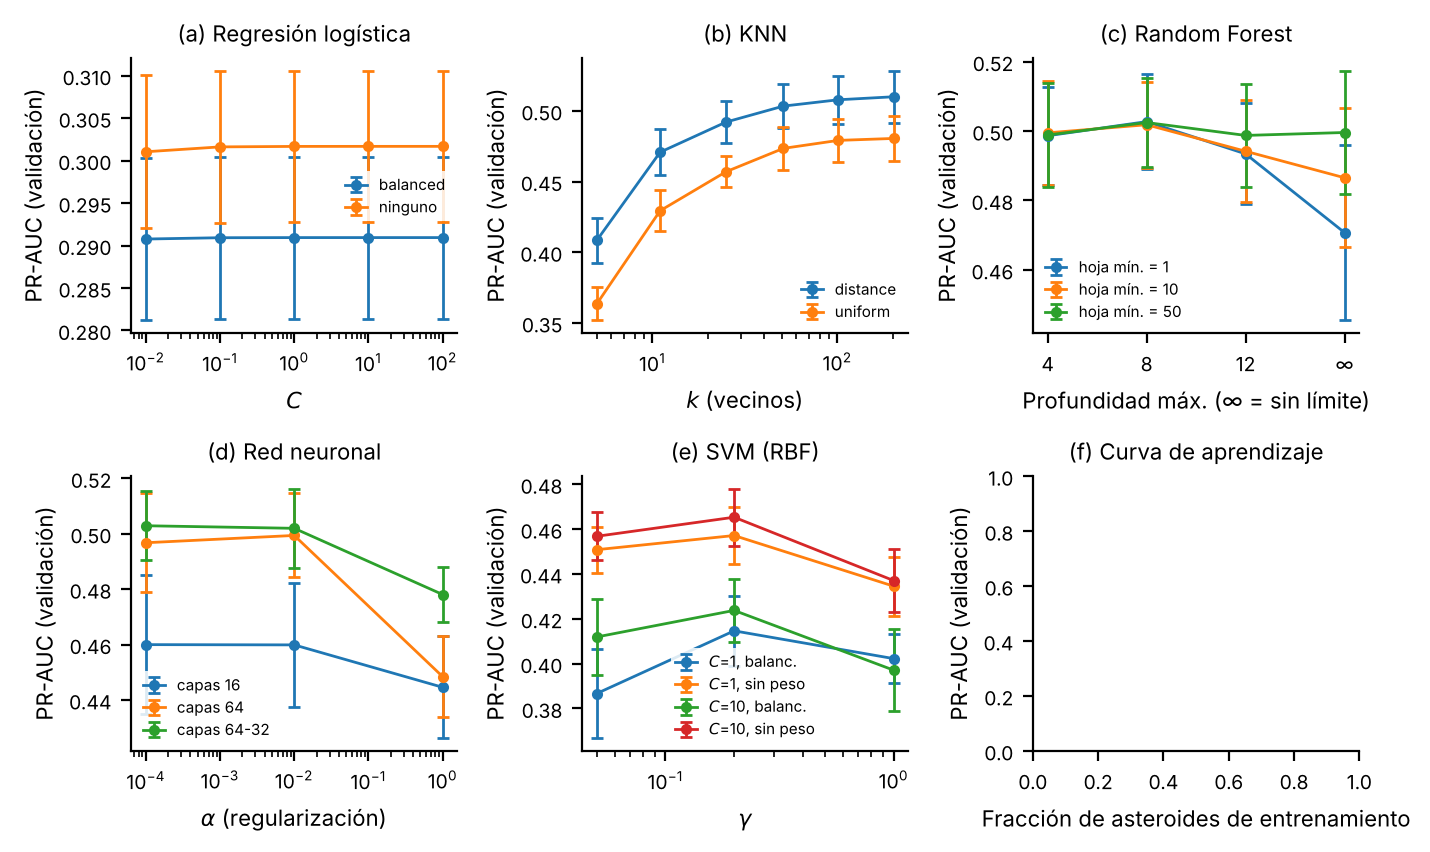

In [6]:
# Figura: efecto de los hiperparámetros (validación) y curva de aprendizaje
LEG = dict(frameon=True, framealpha=0.85, edgecolor="none", fontsize=5.5, handlelength=1.4, borderpad=0.3, labelspacing=0.25)
def lines(ax, m, x, hue, xlabel, logx=False, xticklabels=None, hue_fmt=None):
    a, cols = agg_model(m)
    order = (lambda v: 1e9 if v == 0 else v) if xticklabels else (lambda v: v)      # 0 = "sin límite" va al final
    for h, g in a.groupby(hue):
        g = g.groupby(x).agg(PR_AUC=("PR_AUC", "mean"), PR_sd=("PR_sd", "mean")).reset_index()
        g = g.assign(_o=g[x].map(order)).sort_values("_o")
        lab = hue_fmt(h) if hue_fmt else str(h)
        ax.errorbar(range(len(g)) if xticklabels else g[x], g.PR_AUC, yerr=g.PR_sd, marker="o", ms=3, lw=1, capsize=2, label=lab)
    if xticklabels:
        xs = sorted(a[x].unique(), key=order); ax.set_xticks(range(len(xs))); ax.set_xticklabels([xticklabels(v) for v in xs])
    if logx: ax.set_xscale("log")
    ax.set_xlabel(xlabel); ax.set_ylabel("PR-AUC (validación)")
    ax.legend(loc="best", **LEG)

fig, ax = plt.subplots(2, 3, figsize=(7.0, 4.3))
lines(ax[0, 0], "Regresión logística", "C", "class_weight", "$C$", logx=True); ax[0, 0].set_title("(a) Regresión logística")
lines(ax[0, 1], "KNN", "k", "weights", "$k$ (vecinos)", logx=True); ax[0, 1].set_title("(b) KNN")
lines(ax[0, 2], "Random Forest", "max_depth", "min_samples_leaf", "Profundidad máx. (∞ = sin límite)",
      xticklabels=lambda v: "∞" if v == 0 else str(int(v)), hue_fmt=lambda h: f"hoja mín. = {int(h)}"); ax[0, 2].set_title("(c) Random Forest")
lines(ax[1, 0], "Red neuronal (MLP)", "alpha", "hidden", "$\\alpha$ (regularización)", logx=True, hue_fmt=lambda h: f"capas {h}"); ax[1, 0].set_title("(d) Red neuronal")
a_svm, _ = agg_model("SVM (RBF)")
for (C_, cw), g in a_svm.groupby(["C", "class_weight"]):
    g = g.sort_values("gamma"); ax[1, 1].errorbar(g.gamma, g.PR_AUC, yerr=g.PR_sd, marker="o", ms=3, lw=1, capsize=2,
                                                  label=f"$C$={C_:g}, {'balanc.' if cw == 'balanced' else 'sin peso'}")
ax[1, 1].set_xscale("log"); ax[1, 1].set_xlabel("$\\gamma$"); ax[1, 1].set_ylabel("PR-AUC (validación)")
ax[1, 1].legend(loc="best", **LEG); ax[1, 1].set_title("(e) SVM (RBF)")
ax_lc = ax[1, 2]; ax_lc.set_title("(f) Curva de aprendizaje"); ax_lc.set_xlabel("Fracción de asteroides de entrenamiento"); ax_lc.set_ylabel("PR-AUC (validación)")
fig.tight_layout(); fig_hyper = fig
plt.show()

### Mejor configuración de cada modelo: entrenamiento, validación y prueba

Se reajusta cada mejor configuración (5 pliegues + ajuste final sobre todo el conjunto de desarrollo), se fija el umbral con las predicciones fuera de muestra y se evalúa una sola vez en la prueba. Se añaden dos referencias: un **clasificador constante** (todo PHA) y una **regresión logística que usa solo $H$**.

In [7]:
t0 = time.time()
R = {}
for m in GRIDS:
    R[m] = run_raw(m, best[m])
    print(f"{m}: umbral F1 = {R[m]['thr']:.3f}  ({time.time()-t0:.0f} s)")
R["Solo H (reg. logística)"] = run_raw("Regresión logística", dict(C=1, class_weight="ninguno"), cols=[4])
# Referencia constante: puntuación igual para todos y umbral que marca todo como PHA
const_ev = dict(thr=0.0, s_test=np.zeros(len(yt)), test=metrics(yt, np.zeros(len(yt)), 0.0),
                val=[metrics(yd[b], np.zeros(len(b)), 0.0) for a, b in folds],
                train=[metrics(yd[a], np.zeros(len(a)), 0.0) for a, b in folds])
R["Constante (todo PHA)"] = const_ev

boots = group_bootstrap({lab: (ev["s_test"], ev["thr"]) for lab, ev in R.items()})
MODELS = list(GRIDS)
BASES = ["Solo H (reg. logística)", "Constante (todo PHA)"]
tab_main = results_table(R, boots, MODELS + BASES)
print(f"Evaluación completa en {(time.time()-t0)/60:.1f} min")
display(tab_main.set_index("Modelo").T)

Regresión logística: umbral F1 = 0.121  (1 s)


KNN: umbral F1 = 0.199  (24 s)


Random Forest: umbral F1 = 0.267  (63 s)


Red neuronal (MLP): umbral F1 = 0.199  (92 s)


SVM (RBF): umbral F1 = -1.002  (188 s)


Evaluación completa en 4.4 min


Modelo,Regresión logística,KNN,Random Forest,Red neuronal (MLP),SVM (RBF),Solo H (reg. logística),Constante (todo PHA)
PR_AUC entren.,0.300,1.000,0.591,0.514,0.472,0.272,0.097
PR_AUC valid. (± IC95),0.302 ± 0.011,0.510 ± 0.023,0.503 ± 0.017,0.503 ± 0.015,0.465 ± 0.016,0.275 ± 0.010,0.097 ± 0.000
PR_AUC prueba [IC95],"0.323 [0.287, 0.363]","0.480 [0.442, 0.516]","0.480 [0.441, 0.513]","0.478 [0.438, 0.513]","0.443 [0.411, 0.472]","0.298 [0.265, 0.340]","0.097 [0.086, 0.108]"
ROC_AUC entren.,0.873,1.000,0.932,0.914,0.890,0.863,0.500
ROC_AUC valid. (± IC95),0.873 ± 0.005,0.911 ± 0.007,0.910 ± 0.008,0.910 ± 0.006,0.888 ± 0.005,0.863 ± 0.006,0.500 ± 0.000
ROC_AUC prueba [IC95],"0.878 [0.865, 0.891]","0.907 [0.898, 0.915]","0.910 [0.900, 0.919]","0.909 [0.898, 0.917]","0.883 [0.873, 0.893]","0.873 [0.859, 0.886]","0.500 [0.500, 0.500]"
F1 entren.,0.448,1.000,0.521,0.484,0.445,0.460,0.177
F1 valid. (± IC95),0.448 ± 0.008,0.481 ± 0.014,0.485 ± 0.015,0.481 ± 0.016,0.442 ± 0.008,0.461 ± 0.015,0.177 ± 0.000
F1 prueba [IC95],"0.451 [0.415, 0.485]","0.481 [0.444, 0.514]","0.482 [0.440, 0.517]","0.486 [0.450, 0.518]","0.425 [0.394, 0.452]","0.467 [0.431, 0.500]","0.177 [0.158, 0.194]"


In [8]:
# Resumen por modelo con precisión, recall y exactitud de referencia (prueba)
rows = []
for lab in MODELS + BASES:
    ev, ci = R[lab], boots[lab]
    pred = ev["s_test"] >= ev["thr"]
    rows.append({"Modelo": lab, "Umbral": round(float(ev["thr"]), 3), "Precisión": fmt_test(ev, ci, "Precision"),
                 "Recall": fmt_test(ev, ci, "Recall"), "Exactitud (ref.)": round(float((pred == yt).mean()), 4)})
tab_pr = pd.DataFrame(rows); display(tab_pr)
BEST_MODEL = max(MODELS, key=lambda m: np.mean([v["PR_AUC"] for v in R[m]["val"]]))
print("Mejor modelo por PR-AUC de validación:", BEST_MODEL)

,Modelo,Umbral,Precisión,Recall,Exactitud (ref.)
0,Regresión logística,0.121,"0.314 [0.282, 0.344]","0.801 [0.760, 0.835]",0.8100
1,KNN,0.199,"0.328 [0.295, 0.359]","0.901 [0.879, 0.919]",0.8109
2,Random Forest,0.267,"0.352 [0.313, 0.389]","0.764 [0.722, 0.805]",0.8400
3,Red neuronal (MLP),0.199,"0.327 [0.295, 0.357]","0.949 [0.928, 0.966]",0.8046
4,SVM (RBF),-1.002,"0.327 [0.295, 0.357]","0.607 [0.577, 0.642]",0.8402
5,Solo H (reg. logística),0.098,"0.305 [0.275, 0.335]","0.990 [0.976, 0.999]",0.7800
6,Constante (todo PHA),0.000,"0.097 [0.086, 0.108]","1.000 [1.000, 1.000]",0.0973


Mejor modelo por PR-AUC de validación: KNN


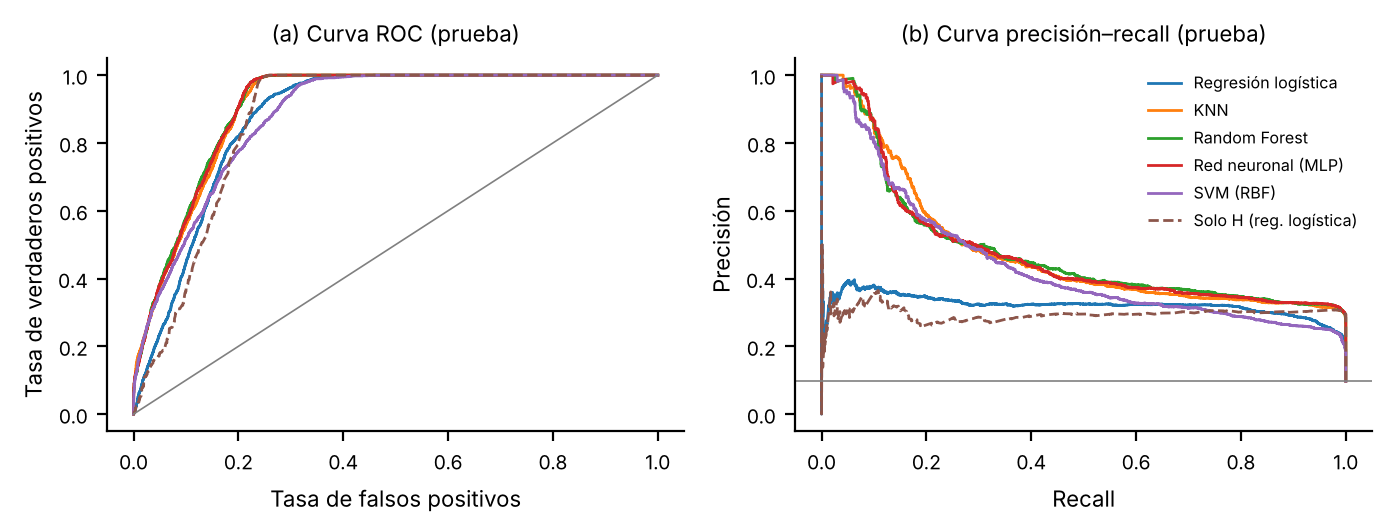

In [9]:
# Figura: curvas ROC y PR en la prueba
fig, ax = plt.subplots(1, 2, figsize=(7.0, 2.7))
for lab in MODELS + ["Solo H (reg. logística)"]:
    s = R[lab]["s_test"]
    fpr, tpr, _ = roc_curve(yt, s); ax[0].plot(fpr, tpr, lw=1, ls="--" if lab.startswith("Solo") else "-", label=lab)
    p_, r_, _ = precision_recall_curve(yt, s); ax[1].plot(r_, p_, lw=1, ls="--" if lab.startswith("Solo") else "-", label=lab)
ax[0].plot([0, 1], [0, 1], color="gray", lw=.6); ax[1].axhline(yt.mean(), color="gray", lw=.6)
ax[0].set_xlabel("Tasa de falsos positivos"); ax[0].set_ylabel("Tasa de verdaderos positivos"); ax[0].set_title("(a) Curva ROC (prueba)")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precisión"); ax[1].set_title("(b) Curva precisión–recall (prueba)")
ax[1].legend(frameon=False, loc="upper right", fontsize=5.8)
fig.tight_layout(); fig_curves = fig
plt.show()

### Curva de aprendizaje y techo de desempeño

La etiqueta oficial depende del MOID, que no está en la base. Para estimar el **techo práctico** se hacen tres comprobaciones: (i) si las cinco familias de modelos convergen a un mismo valor; (ii) si la curva de aprendizaje del mejor modelo se estanca al aumentar los datos; y (iii) cómo se comporta el mejor modelo dentro del subconjunto $H\le22$, único lugar donde la clase es realmente incierta (fuera de él casi todo es negativo).

,frac,mean,std
0,0.10,0.4392,0.0244
1,0.25,0.4720,0.0130
2,0.50,0.4915,0.0186
3,0.75,0.4999,0.0194
4,1.00,0.5100,0.0185


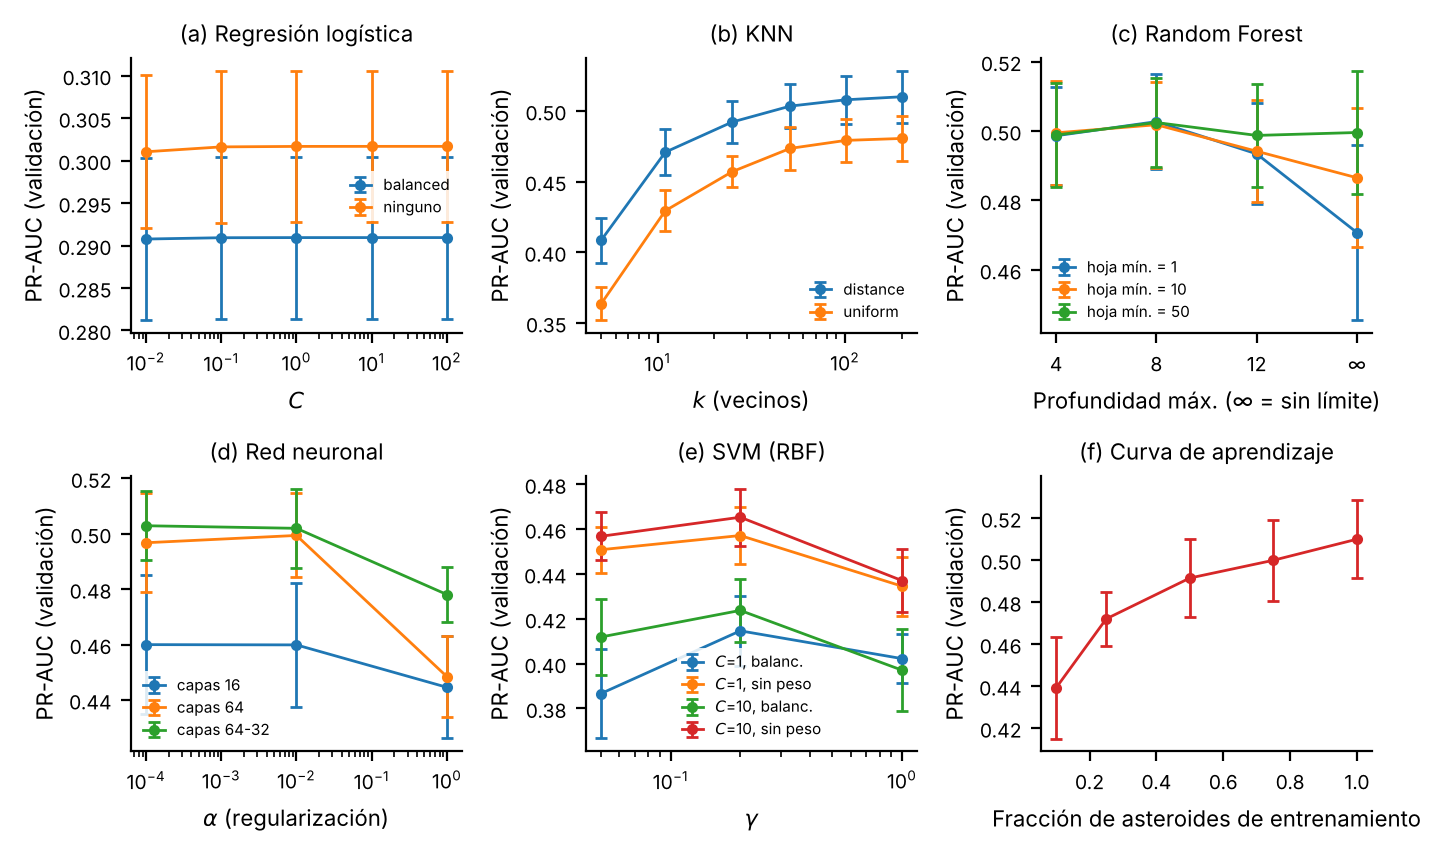

Filas de prueba con H <= 22: 5729 (31.5%); fracción PHA dentro: 0.305
KNN dentro de H<=22:  ROC-AUC = 0.630   PR-AUC = 0.486
Solo H dentro de H<=22:        ROC-AUC = 0.480   PR-AUC = 0.298
Positivos de prueba con H > 22 (no detectables por la regla H<=22): 18 de 1768
PR-AUC de validación por familia: {'Regresión logística': np.float64(0.302), 'KNN': np.float64(0.51), 'Random Forest': np.float64(0.503), 'Red neuronal (MLP)': np.float64(0.503), 'SVM (RBF)': np.float64(0.465)}


In [10]:
def _task_lc(name, p, k, frac):
    a, b = folds[k]
    rng = np.random.RandomState(k)
    ug = np.unique(gd[a]); keep = rng.choice(ug, max(2, int(frac * len(ug))), replace=False)
    sel = a[np.isin(gd[a], keep)]
    s, = fit_scores(name, p, Xd[sel], yd[sel], [Xd[b]], k)
    return average_precision_score(yd[b], s)

fracs = [0.1, 0.25, 0.5, 0.75, 1.0]
jobs = [(f, k) for f in fracs for k in range(K_FOLDS)]
out = Parallel(n_jobs=N_JOBS)(delayed(_task_lc)(BEST_MODEL, best[BEST_MODEL], k, f) for f, k in jobs)
lc = pd.DataFrame([dict(frac=f, fold=k, PR_AUC=o) for (f, k), o in zip(jobs, out)]).groupby("frac").PR_AUC.agg(["mean", "std"]).reset_index()
display(lc.round(4))
ax_lc.errorbar(lc.frac, lc["mean"], yerr=lc["std"], marker="o", ms=3, lw=1, capsize=2, color="C3")
ax_lc.set_ylim(lc["mean"].min() - 0.03, lc["mean"].max() + 0.03)
fig_hyper.tight_layout(); display(fig_hyper)

# Dentro de H <= 22 (donde la clase es incierta), con las predicciones de prueba del mejor modelo
mask = Xt[:, 4] <= 22
s_b = R[BEST_MODEL]["s_test"]
h22 = dict(n=int(mask.sum()), frac_rows=float(mask.mean()), frac_pos=float(yt[mask].mean()),
           roc_model=roc_auc_score(yt[mask], s_b[mask]), pr_model=average_precision_score(yt[mask], s_b[mask]),
           roc_H=roc_auc_score(yt[mask], -Xt[mask, 4]), pr_H=average_precision_score(yt[mask], -Xt[mask, 4]),
           pos_out=int(((yt == 1) & (~mask)).sum()), pos_total=int(yt.sum()))
print(f"Filas de prueba con H <= 22: {mask.sum()} ({mask.mean():.1%}); fracción PHA dentro: {yt[mask].mean():.3f}")
print(f"{BEST_MODEL} dentro de H<=22:  ROC-AUC = {roc_auc_score(yt[mask], s_b[mask]):.3f}   PR-AUC = {average_precision_score(yt[mask], s_b[mask]):.3f}")
Hs = Xt[:, [4]]
print(f"Solo H dentro de H<=22:        ROC-AUC = {roc_auc_score(yt[mask], -Xt[mask, 4]):.3f}   PR-AUC = {average_precision_score(yt[mask], -Xt[mask, 4]):.3f}")
print(f"Positivos de prueba con H > 22 (no detectables por la regla H<=22): {int(((yt==1)&(~mask)).sum())} de {int(yt.sum())}")
best_vals = {m: np.mean([v['PR_AUC'] for v in R[m]['val']]) for m in MODELS}
print("PR-AUC de validación por familia:", {m: round(v, 3) for m, v in best_vals.items()})

### Sensibilidad a la unidad de la velocidad

La base no declara la unidad de `relative_velocity` (la API NeoWs la ofrece en km/s, km/h y mph). Como todo modelo sensible a la escala recibe la variable estandarizada, un cambio de unidad es un reescalado lineal y no debería alterar los resultados. Se verifica en un pliegue.

In [11]:
a, b = folds[0]
unit_tests = {"km/h (supuesta)": 1.0, "km/s": 1 / 3600, "mph": 0.621371}
rows = []
for name in ["Regresión logística", "KNN", "Red neuronal (MLP)", "SVM (RBF)"]:
    row = {"Modelo": name}
    for u, f in unit_tests.items():
        Xs_ = Xd.copy(); Xs_[:, 2] = Xs_[:, 2] * f
        s, = fit_scores(name, best[name], Xs_[a], yd[a], [Xs_[b]], 0)
        row[u] = round(average_precision_score(yd[b], s), 4)
    rows.append(row)
tab_unit = pd.DataFrame(rows); display(tab_unit)

,Modelo,km/h (supuesta),km/s,mph
0,Regresión logística,0.2974,0.2974,0.2974
1,KNN,0.4914,0.4914,0.4914
2,Red neuronal (MLP),0.4920,0.4920,0.4920
3,SVM (RBF),0.4438,0.4438,0.4438


# 4. Reducción de dimensión

Se evalúan los **dos mejores modelos** de la sección 3 (por PR-AUC de validación) con hiperparámetros fijos en los valores ya seleccionados.

## 4.1 Análisis individual de variables

Para cada variable (sobre el conjunto de desarrollo) se calculan: la correlación de Spearman con la etiqueta, el AUC univariado y su índice de discriminación ($2|{\rm AUC}-0.5|$), la información mutua con la etiqueta, la máxima correlación con otra variable (redundancia) y el cambio de PR-AUC de validación al **eliminar** la variable del mejor modelo.

In [12]:
TOP2 = sorted(MODELS, key=lambda m: -best_vals[m])[:2]
print("Dos mejores modelos:", TOP2)

rho = [abs(stats.spearmanr(Xd[:, j], yd)[0]) for j in range(5)]
auc_u = [roc_auc_score(yd, Xd[:, j]) for j in range(5)]
auc_u = [max(a_, 1 - a_) for a_ in auc_u]
mi = mutual_info_classif(Xd, yd, random_state=SEED, n_neighbors=5)
cm = np.abs(pd.DataFrame(Xd).corr(method="spearman").to_numpy()); np.fill_diagonal(cm, 0)
max_corr = cm.max(axis=1)

def _task_lofo(name, p, cols, k):
    a, b = folds[k]
    s, = fit_scores(name, p, Xd[a][:, cols], yd[a], [Xd[b][:, cols]], k)
    return average_precision_score(yd[b], s)

variants = {"todas": list(range(5))}
variants.update({FEATURES[j]: [c for c in range(5) if c != j] for j in range(5)})
jobs = [(v, k) for v in variants for k in range(K_FOLDS)]
out = Parallel(n_jobs=N_JOBS)(delayed(_task_lofo)(TOP2[0], best[TOP2[0]], variants[v], k) for v, k in jobs)
lofo = pd.DataFrame([dict(v=v, k=k, pr=o) for (v, k), o in zip(jobs, out)]).groupby("v").pr.mean()
tab_ind = pd.DataFrame({"Variable": FEATURES, "|ρ| Spearman": np.round(rho, 3), "AUC univariado": np.round(auc_u, 3),
                        "Índice discr. (2|AUC−0.5|)": np.round([2 * abs(a_ - 0.5) for a_ in auc_u], 3),
                        "Info. mutua": np.round(mi, 4), "Máx. |ρ| con otra": np.round(max_corr, 3),
                        f"Δ PR-AUC al eliminar ({TOP2[0]})": [round(lofo[f] - lofo["todas"], 4) for f in FEATURES]})
display(tab_ind)
print(f"PR-AUC de validación con todas las variables ({TOP2[0]}): {lofo['todas']:.4f}")
print("Candidatas a eliminar: variables con máx. |ρ| >= 0.95 (redundantes) o índice de discriminación bajo y Δ PR-AUC ≈ 0.")

Dos mejores modelos: ['KNN', 'Red neuronal (MLP)']


,Variable,|ρ| Spearman,AUC univariado,Índice discr. (2|AUC−0.5|),Info. mutua,Máx. |ρ| con otra,Δ PR-AUC al eliminar (KNN)
0,log10 d_min,0.373,0.863,0.726,0.1466,1.000,-0.0002
1,log10 d_max,0.373,0.863,0.726,0.1462,1.000,-0.0002
2,velocidad,0.188,0.683,0.366,0.0216,0.339,-0.0383
3,dist. de paso,0.043,0.542,0.084,0.0061,0.327,-0.1458
4,H,0.373,0.863,0.726,0.1453,1.000,-0.0002


PR-AUC de validación con todas las variables (KNN): 0.5100
Candidatas a eliminar: variables con máx. |ρ| >= 0.95 (redundantes) o índice de discriminación bajo y Δ PR-AUC ≈ 0.


### ¿Por qué pesa `miss_distance` si sola discrimina poco?

Su AUC univariado es bajo (0.54), pero eliminarla del mejor modelo reduce mucho la PR-AUC. Una razón física: la distancia de paso en una aproximación **nunca es menor que el MOID** del asteroide. Por tanto, si un objeto con $H\le22$ pasa a menos de 0.05 ua, su MOID cumple $\le 0.05$ ua y es PHA. Se comprueba con los datos (análisis descriptivo sobre toda la base).

In [ ]:
AU_KM = 149597870.7
lim = 0.05 * AU_KM                                    # 0.05 ua en km (umbral de MOID de la definición de PHA)
H_, d_, y_ = df.absolute_magnitude, df.miss_distance, df.hazardous.astype(int)
grupos = {"H <= 22 y dist. <= 0.05 ua": (H_ <= 22) & (d_ <= lim),
          "H <= 22 y dist. > 0.05 ua": (H_ <= 22) & (d_ > lim),
          "H > 22": H_ > 22}
tab_regla = pd.DataFrame([(k, int(m.sum()), int(y_[m].sum()), round(float(y_[m].mean()), 4)) for k, m in grupos.items()],
                         columns=["Grupo de filas", "Filas", "PHA", "Fracción PHA"])
display(tab_regla)
r = grupos["H <= 22 y dist. <= 0.05 ua"]
print(f"La regla 'H<=22 y distancia<=0.05 ua' cubre {int(y_[r].sum())} de {int(y_.sum())} filas PHA ({y_[r].sum()/y_.sum():.1%}) con precisión {y_[r].mean():.3f}")

,Grupo de filas,Filas,PHA,Fracción PHA
0,H <= 22 y dist. <= 0.05 ua,593,580,0.9781
1,H <= 22 y dist. > 0.05 ua,28508,8170,0.2866
2,H > 22,61735,90,0.0015


La regla 'H<=22 y distancia<=0.05 ua' cubre 580 de 8840 filas PHA (6.6%) con precisión 0.978


## 4.2 Extracción de características lineal: PCA

Se aplica PCA sobre las variables estandarizadas, **ajustado dentro de cada pliegue** (solo con entrenamiento). Se comparan dos entradas: las 5 variables y las 3 variables independientes (se eliminan a mano los dos diámetros, redundantes con $H$). **Criterio para el número de componentes:** el menor $k$ cuya varianza explicada acumulada (en desarrollo) es $\ge 99\,\%$; se contrasta con el PR-AUC de validación para cada $k$.

In [13]:
SETS = {"5 variables": [0, 1, 2, 3, 4], "3 variables (sin diámetros)": [2, 3, 4]}
KMAX = {"5 variables": 4, "3 variables (sin diámetros)": 3}

def pca_arrays(cols):
    """Devuelve (lista Ztr por pliegue, lista Zva por pliegue, Zdev, Ztest, varianza explicada) con PCA ajustado solo con entrenamiento."""
    tr, va = [], []
    for a, b in folds:
        sc = StandardScaler().fit(Xd[a][:, cols]); pc = PCA().fit(sc.transform(Xd[a][:, cols]))
        tr.append(pc.transform(sc.transform(Xd[a][:, cols]))); va.append(pc.transform(sc.transform(Xd[b][:, cols])))
    sc = StandardScaler().fit(Xd[:, cols]); pc = PCA().fit(sc.transform(Xd[:, cols]))
    return tr, va, pc.transform(sc.transform(Xd[:, cols])), pc.transform(sc.transform(Xt[:, cols])), pc.explained_variance_ratio_

t0 = time.time()
PCA_R, PCA_EVR, PCA_K = {}, {}, {}
for sname, cols in SETS.items():
    tr, va, Zdev, Ztest, evr = pca_arrays(cols)
    PCA_EVR[sname] = evr
    PCA_K[sname] = int(np.argmax(np.cumsum(evr) >= 0.99) + 1)
    print(f"{sname}: varianza explicada por componente = {np.round(evr, 4)}  -> k (>=99 %) = {PCA_K[sname]}")
    for k in range(1, KMAX[sname] + 1):
        for m in TOP2:
            PCA_R[(sname, k, m)] = run_model(m, best[m], [z[:, :k] for z in tr], [z[:, :k] for z in va], Zdev[:, :k], Ztest[:, :k])
    print(f"   listo ({(time.time()-t0)/60:.1f} min)")

5 variables: varianza explicada por componente = [0.6598 0.2079 0.1323 0.     0.    ]  -> k (>=99 %) = 3


   listo (2.5 min)
3 variables (sin diámetros): varianza explicada por componente = [0.545  0.2464 0.2085]  -> k (>=99 %) = 3


   listo (4.1 min)


In [14]:
items = {f"PCA|{s}|{k}|{m}": (ev["s_test"], ev["thr"]) for (s, k, m), ev in PCA_R.items()}
for m in TOP2:
    items[f"BASE|{m}"] = (R[m]["s_test"], R[m]["thr"])
boot_pca = group_bootstrap(items, B=300)

rows = []
for (s, k, m), ev in PCA_R.items():
    ci = boot_pca[f"PCA|{s}|{k}|{m}"]
    rows.append({"Entrada": s, "k": k, "Reducción (%)": round(100 * (1 - k / 5)), "Modelo": m,
                 "PR-AUC valid.": fmt_val(ev["val"], "PR_AUC"), "PR-AUC prueba": fmt_test(ev, ci, "PR_AUC"),
                 "ROC-AUC valid.": fmt_val(ev["val"], "ROC_AUC"), "F1 valid.": fmt_val(ev["val"], "F1"), "F1 prueba": fmt_test(ev, ci, "F1")})
for m in TOP2:
    ev, ci = R[m], boots[m]
    rows.append({"Entrada": "Original (5 variables)", "k": 5, "Reducción (%)": 0, "Modelo": m,
                 "PR-AUC valid.": fmt_val(ev["val"], "PR_AUC"), "PR-AUC prueba": fmt_test(ev, ci, "PR_AUC"),
                 "ROC-AUC valid.": fmt_val(ev["val"], "ROC_AUC"), "F1 valid.": fmt_val(ev["val"], "F1"), "F1 prueba": fmt_test(ev, ci, "F1")})
tab_pca = pd.DataFrame(rows); display(tab_pca)

,Entrada,k,Reducción (%),Modelo,PR-AUC valid.,PR-AUC prueba,ROC-AUC valid.,F1 valid.,F1 prueba
0,5 variables,1,80,KNN,0.312 ± 0.019,"0.310 [0.273, 0.352]",0.859 ± 0.008,0.410 ± 0.010,"0.418 [0.386, 0.447]"
1,5 variables,1,80,Red neuronal (MLP),0.288 ± 0.005,"0.287 [0.258, 0.323]",0.863 ± 0.006,0.427 ± 0.012,"0.428 [0.395, 0.462]"
2,5 variables,2,60,KNN,0.401 ± 0.016,"0.396 [0.354, 0.443]",0.892 ± 0.005,0.463 ± 0.013,"0.467 [0.434, 0.500]"
3,5 variables,2,60,Red neuronal (MLP),0.390 ± 0.013,"0.382 [0.336, 0.427]",0.895 ± 0.005,0.466 ± 0.014,"0.463 [0.431, 0.500]"
4,5 variables,3,40,KNN,0.507 ± 0.020,"0.481 [0.444, 0.518]",0.910 ± 0.006,0.478 ± 0.011,"0.476 [0.444, 0.509]"
5,5 variables,3,40,Red neuronal (MLP),0.499 ± 0.024,"0.481 [0.443, 0.514]",0.910 ± 0.007,0.485 ± 0.017,"0.479 [0.445, 0.514]"
6,5 variables,4,20,KNN,0.507 ± 0.019,"0.481 [0.443, 0.520]",0.909 ± 0.006,0.478 ± 0.011,"0.476 [0.443, 0.509]"
7,5 variables,4,20,Red neuronal (MLP),0.502 ± 0.018,"0.464 [0.423, 0.498]",0.910 ± 0.006,0.482 ± 0.011,"0.482 [0.449, 0.516]"
8,3 variables (sin diámetros),1,80,KNN,0.205 ± 0.010,"0.210 [0.178, 0.240]",0.736 ± 0.007,0.279 ± 0.008,"0.275 [0.251, 0.301]"
9,3 variables (sin diámetros),1,80,Red neuronal (MLP),0.219 ± 0.015,"0.207 [0.179, 0.232]",0.769 ± 0.014,0.306 ± 0.016,"0.302 [0.270, 0.326]"


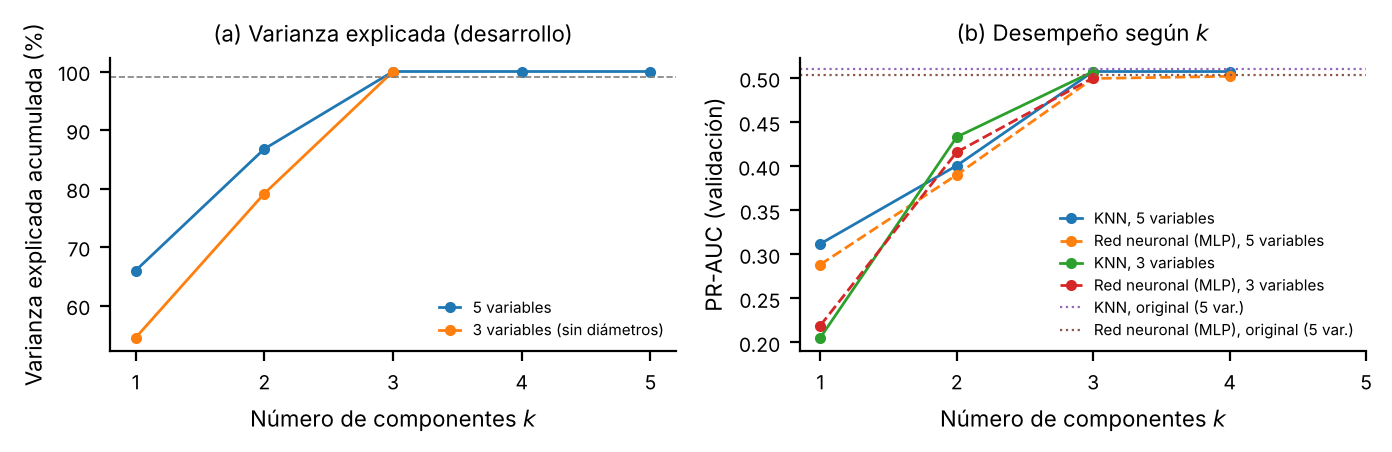

In [15]:
# Figura: PCA
fig, ax = plt.subplots(1, 2, figsize=(7.0, 2.3))
for sname, evr in PCA_EVR.items():
    ax[0].plot(range(1, len(evr) + 1), np.cumsum(evr) * 100, marker="o", ms=3, lw=1, label=sname)
ax[0].axhline(99, color="gray", ls="--", lw=.6); ax[0].set_xlabel("Número de componentes $k$"); ax[0].set_ylabel("Varianza explicada acumulada (%)")
ax[0].set_title("(a) Varianza explicada (desarrollo)"); ax[0].legend(loc="lower right", **LEG)
for (sname, m), ls in zip([(s, m) for s in SETS for m in TOP2], ["-", "--", "-", "--"]):
    ks = list(range(1, KMAX[sname] + 1))
    mu = [np.mean([v["PR_AUC"] for v in PCA_R[(sname, k, m)]["val"]]) for k in ks]
    ax[1].plot(ks, mu, marker="o", ms=3, lw=1, ls=ls, label=f"{m}, {sname.split(' (')[0]}")
for i, m in enumerate(TOP2):
    ax[1].axhline(np.mean([v["PR_AUC"] for v in R[m]["val"]]), color=f"C{i+4}", lw=.8, ls=":", label=f"{m}, original (5 var.)")
ax[1].set_xlabel("Número de componentes $k$"); ax[1].set_ylabel("PR-AUC (validación)"); ax[1].set_title("(b) Desempeño según $k$")
ax[1].legend(loc="lower right", **LEG)
for a_ in ax: a_.set_xticks(range(1, 6))
fig.tight_layout(); fig_pca = fig
plt.show()

## 4.3 Extracción de características no lineal: UMAP

**A. Evaluación.** UMAP (`n_neighbors=15`, `min_dist=0.1`, distancia euclídea, **sin usar la etiqueta**) se ajusta **dentro de cada pliegue solo con el entrenamiento**, y la validación se proyecta con `transform`. Se prueban $n_{\rm comp}\in\{2,3,4\}$ sobre las 5 variables estandarizadas. **Criterio:** el $n_{\rm comp}$ con mayor PR-AUC de validación promedio entre los dos modelos; la prueba se reporta para los tres valores solo como comparación.

In [16]:
def umap_fold(nc, k):
    a, b = folds[k]
    sc = StandardScaler().fit(Xd[a]); um = umap.UMAP(n_components=nc, n_neighbors=15, min_dist=0.1, random_state=SEED)
    Ztr = um.fit_transform(sc.transform(Xd[a])); Zva = um.transform(sc.transform(Xd[b]))
    return {m: _fit_eval(m, best[m], Ztr, yd[a], Zva, k) for m in TOP2}

t0 = time.time()
UMAP_R, UMAP_EMB = {}, {}
NCS = [2, 3, 4]
for nc in NCS:
    per_fold = Parallel(n_jobs=N_JOBS)(delayed(umap_fold)(nc, k) for k in range(K_FOLDS))
    sc = StandardScaler().fit(Xd); um = umap.UMAP(n_components=nc, n_neighbors=15, min_dist=0.1, random_state=SEED)
    Zdev = um.fit_transform(sc.transform(Xd)); Ztest = um.transform(sc.transform(Xt))
    if nc == 2: UMAP_EMB = (Zdev, yd)
    for m in TOP2:
        s_test, = fit_scores(m, best[m], Zdev, yd, [Ztest], seed=99)
        UMAP_R[(nc, m)] = collect([per_fold[k][m] for k in range(K_FOLDS)], s_test)
    print(f"UMAP n_comp={nc}: listo ({(time.time()-t0)/60:.1f} min)")

UMAP n_comp=2: listo (5.5 min)


UMAP n_comp=3: listo (10.9 min)


UMAP n_comp=4: listo (16.7 min)


,Entrada,n_comp,Reducción (%),Modelo,PR-AUC valid.,PR-AUC prueba,ROC-AUC valid.,F1 valid.,F1 prueba
0,UMAP,2,60,KNN,0.402 ± 0.007,"0.404 [0.366, 0.440]",0.895 ± 0.003,0.459 ± 0.011,"0.457 [0.425, 0.488]"
1,UMAP,2,60,Red neuronal (MLP),0.384 ± 0.008,"0.369 [0.327, 0.421]",0.891 ± 0.006,0.454 ± 0.013,"0.457 [0.423, 0.495]"
2,UMAP,3,40,KNN,0.466 ± 0.012,"0.441 [0.404, 0.476]",0.905 ± 0.005,0.473 ± 0.012,"0.469 [0.435, 0.502]"
3,UMAP,3,40,Red neuronal (MLP),0.477 ± 0.018,"0.441 [0.402, 0.476]",0.908 ± 0.006,0.473 ± 0.015,"0.468 [0.434, 0.500]"
4,UMAP,4,20,KNN,0.466 ± 0.016,"0.441 [0.403, 0.477]",0.906 ± 0.006,0.474 ± 0.012,"0.471 [0.437, 0.504]"
5,UMAP,4,20,Red neuronal (MLP),0.483 ± 0.013,"0.447 [0.403, 0.483]",0.909 ± 0.006,0.481 ± 0.014,"0.478 [0.442, 0.511]"


PR-AUC de validación promedio por n_comp: {2: np.float64(0.3932), 3: np.float64(0.4717), 4: np.float64(0.4745)} -> elegido: 4


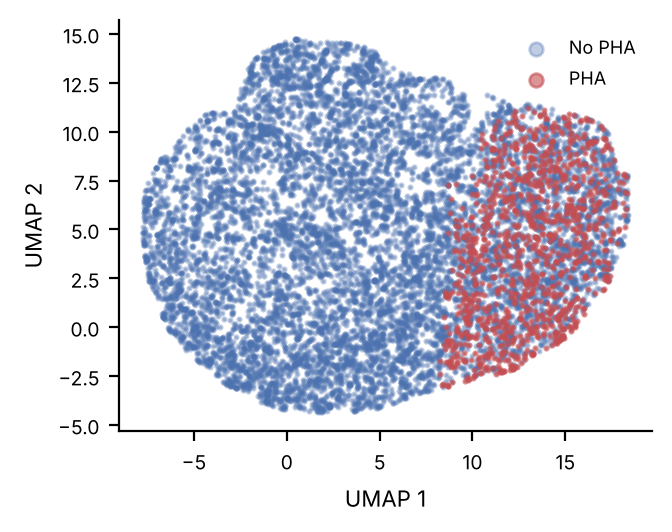

In [17]:
items = {f"UMAP|{nc}|{m}": (ev["s_test"], ev["thr"]) for (nc, m), ev in UMAP_R.items()}
boot_umap = group_bootstrap(items, B=300)
rows = []
for (nc, m), ev in UMAP_R.items():
    ci = boot_umap[f"UMAP|{nc}|{m}"]
    rows.append({"Entrada": "UMAP", "n_comp": nc, "Reducción (%)": round(100 * (1 - nc / 5)), "Modelo": m,
                 "PR-AUC valid.": fmt_val(ev["val"], "PR_AUC"), "PR-AUC prueba": fmt_test(ev, ci, "PR_AUC"),
                 "ROC-AUC valid.": fmt_val(ev["val"], "ROC_AUC"), "F1 valid.": fmt_val(ev["val"], "F1"), "F1 prueba": fmt_test(ev, ci, "F1")})
tab_umap = pd.DataFrame(rows); display(tab_umap)
mean_val = {nc: np.mean([np.mean([v["PR_AUC"] for v in UMAP_R[(nc, m)]["val"]]) for m in TOP2]) for nc in NCS}
NC_BEST = max(mean_val, key=mean_val.get)
print("PR-AUC de validación promedio por n_comp:", {k: round(v, 4) for k, v in mean_val.items()}, "-> elegido:", NC_BEST)

# Figura: proyección UMAP 2D
Z2, y2 = UMAP_EMB
sel = np.random.RandomState(0).choice(len(y2), min(12000, len(y2)), replace=False)
fig, ax = plt.subplots(figsize=(3.4, 2.7))
ax.scatter(Z2[sel][y2[sel] == 0, 0], Z2[sel][y2[sel] == 0, 1], s=1.5, c="#4C72B0", alpha=.35, label="No PHA", rasterized=True)
ax.scatter(Z2[sel][y2[sel] == 1, 0], Z2[sel][y2[sel] == 1, 1], s=1.5, c="#C44E52", alpha=.6, label="PHA", rasterized=True)
ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2"); ax.legend(frameon=False, markerscale=4, loc="best")
fig.tight_layout(); fig_umap = fig
plt.show()

# 5. Discusión y conclusiones

Comparación global en la **prueba** (asteroides no vistos): referencias, los cinco modelos con las 5 variables originales, y los dos mejores modelos con PCA y UMAP.

In [18]:
rows = []
for lab in BASES + MODELS:
    ev, ci = R[lab], boots[lab]
    rows.append({"Configuración": lab, "Variables": "5" if lab in MODELS else ("1" if lab.startswith("Solo") else "—"),
                 "PR-AUC": fmt_test(ev, ci, "PR_AUC"), "ROC-AUC": fmt_test(ev, ci, "ROC_AUC"), "F1": fmt_test(ev, ci, "F1")})
for (s, k, m), ev in PCA_R.items():
    if k == PCA_K[s]:
        ci = boot_pca[f"PCA|{s}|{k}|{m}"]
        rows.append({"Configuración": f"{m} + PCA ({s})", "Variables": str(k), "PR-AUC": fmt_test(ev, ci, "PR_AUC"),
                     "ROC-AUC": fmt_test(ev, ci, "ROC_AUC"), "F1": fmt_test(ev, ci, "F1")})
for m in TOP2:
    ev, ci = UMAP_R[(NC_BEST, m)], boot_umap[f"UMAP|{NC_BEST}|{m}"]
    rows.append({"Configuración": f"{m} + UMAP", "Variables": str(NC_BEST), "PR-AUC": fmt_test(ev, ci, "PR_AUC"),
                 "ROC-AUC": fmt_test(ev, ci, "ROC_AUC"), "F1": fmt_test(ev, ci, "F1")})
tab_final = pd.DataFrame(rows); display(tab_final)
print(f"Tiempo total de ejecución: {(time.time()-t_start)/60:.1f} min")

,Configuración,Variables,PR-AUC,ROC-AUC,F1
0,Solo H (reg. logística),1,"0.298 [0.265, 0.340]","0.873 [0.859, 0.886]","0.467 [0.431, 0.500]"
1,Constante (todo PHA),—,"0.097 [0.086, 0.108]","0.500 [0.500, 0.500]","0.177 [0.158, 0.194]"
2,Regresión logística,5,"0.323 [0.287, 0.363]","0.878 [0.865, 0.891]","0.451 [0.415, 0.485]"
3,KNN,5,"0.480 [0.442, 0.516]","0.907 [0.898, 0.915]","0.481 [0.444, 0.514]"
4,Random Forest,5,"0.480 [0.441, 0.513]","0.910 [0.900, 0.919]","0.482 [0.440, 0.517]"
5,Red neuronal (MLP),5,"0.478 [0.438, 0.513]","0.909 [0.898, 0.917]","0.486 [0.450, 0.518]"
6,SVM (RBF),5,"0.443 [0.411, 0.472]","0.883 [0.873, 0.893]","0.425 [0.394, 0.452]"
7,KNN + PCA (5 variables),3,"0.481 [0.444, 0.518]","0.905 [0.896, 0.915]","0.476 [0.444, 0.509]"
8,Red neuronal (MLP) + PCA (5 variables),3,"0.481 [0.443, 0.514]","0.910 [0.901, 0.918]","0.479 [0.445, 0.514]"
9,KNN + PCA (3 variables (sin diámetros)),3,"0.481 [0.444, 0.518]","0.905 [0.896, 0.915]","0.476 [0.444, 0.509]"


Tiempo total de ejecución: 49.7 min


**Lectura de los resultados** (cifras de las tablas anteriores; PR-AUC y ROC-AUC de prueba salvo que se indique):

- **Modelos.** KNN, Random Forest y red neuronal empatan dentro de sus intervalos de confianza (PR-AUC 0.478 a 0.480; ROC-AUC 0.907 a 0.910; $F_1\approx0.48$). La regresión logística (0.323; 0.878) y el SVM (0.443; 0.883) quedan por debajo; el SVM se entrenó con una submuestra, lo que pudo influir. Frente a usar solo $H$ (PR-AUC 0.298; ROC-AUC 0.873) la mejora es clara en PR-AUC y ROC-AUC, pero pequeña en $F_1$ (0.467 frente a 0.48, con intervalos que se solapan). La exactitud engaña: el clasificador constante tiene $F_1=0.177$ con la regresión logística y solo $H$ ya se alcanza 0.467.
- **Techo de desempeño.** Tres familias muy distintas convergen al mismo valor y la curva de aprendizaje muestra rendimientos decrecientes (de 75 % a 100 % de los datos la PR-AUC sube 0.010, menos que su variación entre pliegues, 0.019). Dentro del grupo $H\le22$, donde la clase es incierta, el mejor modelo alcanza ROC-AUC 0.63, mientras que $H$ sola no tiene señal (0.48). Esto sugiere un techo práctico cercano a ROC-AUC 0.91 y PR-AUC 0.48 a 0.51 con estas variables; no es un máximo teórico, que solo podría calcularse con el MOID.
- **`miss_distance`.** Sola discrimina poco (AUC 0.54), pero eliminarla baja la PR-AUC en 0.146: el 97.8 % de las filas con $H\le22$ y distancia de paso $\le0.05$ ua son PHA (la distancia de paso no es menor que el MOID), aunque esas filas son solo el 6.6 % de los PHA.
- **Redundancia y PCA.** Eliminar cualquiera de $H$, $\log_{10}d_{\min}$ o $\log_{10}d_{\max}$ no cambia el desempeño (Δ PR-AUC ≈ 0), porque las otras dos conservan la información. PCA con $k=3$ explica el 100 % de la varianza (los dos componentes restantes tienen varianza cero) y mantiene el desempeño con 40 % menos variables; con $k=2$ la PR-AUC de validación cae a 0.39 a 0.43. Eliminar los diámetros a mano antes de PCA da el mismo resultado: idéntico en KNN (el z-score posterior por componente hace que ambas entradas definan el mismo espacio) y dentro del intervalo de confianza en la red neuronal.
- **UMAP.** Con 3 o 4 componentes queda algo por debajo de las variables originales (PR-AUC 0.44 a 0.45 frente a 0.48) y con 2 componentes baja a 0.37 a 0.40; no aporta frente a las variables originales ni a PCA.
- **Unidad de la velocidad.** Cambiarla (km/h, km/s, mph) no altera ningún resultado.